In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('data/QuizData.csv')
df.head()

,total,reception
0,118,62
1,253,148
2,320,201
3,94,80
4,155,92


In [3]:
data = df.iloc[:, :-1].values # 처음부터 마지막 컬럼 직전까지의 데이터 (독립 변수 - 원인)
label = df.iloc[:, -1].values # 마지막 컬럼 데이터 (종속 변수 - 결과)
# 훈련데이터, 테스트데이터 분류
train_data, test_data, train_label, test_label = train_test_split(
data, label, random_state=42)  # 회귀 : stratify 사용하지 않음

lr = LinearRegression() # 객체 생성
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
print('예측 : ',predict)

예측 :  [ 84.12419052 154.14143753 135.17843313 149.76535959 117.1878905 ]


In [4]:
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('학습데이터 예측 : ',score)
print('테스트데이터 예측 : ',score2)

in_data = lr.predict([[300]])
print("예측인원 : ",in_data)

학습데이터 예측 :  0.8825725967876883
테스트데이터 예측 :  0.8071218004663635
예측인원 :  [172.61821104]


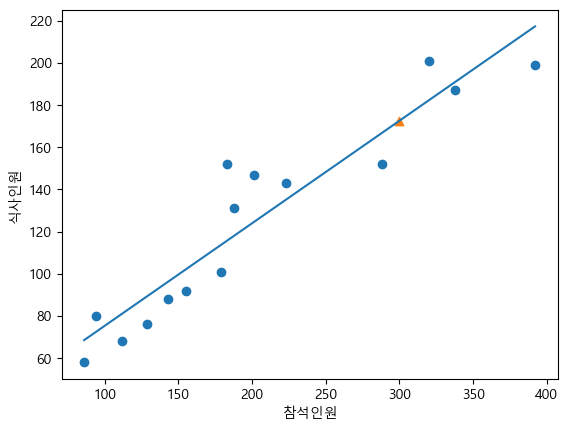

In [6]:
# 산점도 그래프
plt.scatter(train_data, train_label)
plt.scatter(300, 172.61, marker='^')
# plt.plot(train_data, lr.predict(train_data), color='green') # 선 그래프
plt.plot([86,392],[86*lr.coef_+lr.intercept_,392*lr.coef_+lr.intercept_])
plt.xlabel('참석인원')
plt.ylabel('식사인원')
plt.show()